# 1.1数据的引出与准备

In [2]:
#库的导入
import json
import re
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
from pyecharts import options as opts
from pyecharts.charts import Bar, Boxplot, Map, Pie, WordCloud

## 1.1重庆成都地区的数据分析师的数据前期检查

In [3]:
dfcq=pd.read_json(r"C:\Users\A\PycharmProjects\JupyterProject3\data\sample_data_cq.json")#重庆地区数据集
cq=dfcq.head(3)
dfcd=pd.read_json(r"C:\Users\A\PycharmProjects\JupyterProject3\data\sample_data_cd.json")#成都
cd=dfcd.head(3)
print(cq)
print(cd)

             job_id                   title      company salary salary_source  \
0  6c041b0c73eec5ae             数据分析师可带新人双休  江北区乾阳商贸部...   7-9K           api   
1  2a0482a51fea002d             数据分析（无经验小白）         风林火山   4-7K           api   
2  dac430cd9947c72d  商业数据分析+周末双休+朝9晚5+轻松不加班      重庆叙驰洲商贸  5-10K           api   

     location boss_active_status     tags_list skill_tags  \
0  重庆·渝中区·解放碑              3日内活跃  经验不限 | 中专/中技         []   
1   重庆·南岸区·南坪               刚刚活跃     经验不限 | 本科  [kanzhun]   
2  重庆·渝中区·渝州路               刚刚活跃   1-3年 | 学历不限         []   

                                                  jd  
0  双休\n客服\n专员\n岗位职责：\n1、负责日常业务数据的收集、整理与清洗，确保数据源的准...  
1  数据分析/挖掘经验\n计算机相关专业\n电商/零售行业数据相关经验\n数学/统计相关专业\n...  
2  职位类型：\n商业数据分析\n薪资待遇：底薪4800+200全勤+提成，\n上班时间：早上9...  
             job_id      title      company salary salary_source    location  \
0  3953c37571f798ef  数据助理（可双休）  成都悠鑫龙商务信...   6-7K           api  成都·锦江区·红星路   
1  89795d706a7b9c9e     大数据分析师      河南车柿供应链  7-10K

## 1.2成都重庆地区数据分析师合并

In [4]:
# 增加城市标签，在内存中合并成一张表
dfcq["city"] = "重庆"
dfcd["city"] = "成都"
df_all = pd.concat([dfcq, dfcd], ignore_index=True)
print(f"重庆+成都总数据量：{len(df_all)}")

#过滤：只保留数据分析岗
before = len(df_all)

# 标题命中数据分析核心词，且不含排除词（排除运维/开发/讲师/标注等非分析岗）
keep_kw = r"(?i)数据分析|商业分析|bi分析师|数据挖掘|数据治理|数据运营"
drop_kw = r"标注|运维|开发|讲师|数据库|审计|实验室|药物|情感|恋爱|视频镜头|量化|策略分析|供应链|财务分析"
mask_title = (df_all["title"].str.contains(keep_kw, regex=True, na=False)
              & ~df_all["title"].str.contains(drop_kw, regex=True, na=False))

df_all = df_all[mask_title].reset_index(drop=True)
print(f"过滤前 {before} 条 -> 过滤后 {len(df_all)} 条，剔除非数据分析岗 {before - len(df_all)} 条")

# 加工列（薪资 / 经验 / 学历）在下面的 2.1、2.2 两个单元格里分别生成


重庆+成都总数据量：84
过滤前 84 条 -> 过滤后 58 条，剔除非数据分析岗 26 条


## 1.3查看数据名

In [5]:
#查看有多少数据名
df_all.info()
# 查看数据量
df_all.shape

<class 'pandas.DataFrame'>
RangeIndex: 58 entries, 0 to 57
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   job_id              58 non-null     str   
 1   title               58 non-null     str   
 2   company             58 non-null     str   
 3   salary              58 non-null     str   
 4   salary_source       58 non-null     str   
 5   location            58 non-null     str   
 6   boss_active_status  58 non-null     str   
 7   tags_list           58 non-null     str   
 8   skill_tags          58 non-null     object
 9   jd                  58 non-null     str   
 10  city                58 non-null     str   
dtypes: object(1), str(10)
memory usage: 5.1+ KB


(58, 11)

## 2.1数据清洗

In [6]:
def process_salary(salary):
    if not isinstance(salary, str):
        return np.nan

    # 处理日薪
    if '元/天' in salary:
        # 提取第一个数值（-前面的数值）
        daily = float(re.findall(r'(\d+\.?\d*)', salary.split('-')[0])[0])
        return daily * 30 / 1000  # 转换为月薪(千元)，按30天计算

    # 处理时薪
    elif '元/时' in salary:
        # 提取第一个数值（-前面的数值）
        hourly = float(re.findall(r'(\d+\.?\d*)', salary.split('-')[0])[0])
        return hourly * 8 * 30 / 1000  # 转换为月薪(千元)，8小时/天，30天/月

    # 处理月薪
    elif 'K' in salary or 'k' in salary:
        # 提取第一个数值（-前面的数值）
        monthly = float(re.findall(r'(\d+\.?\d*)', salary.split('-')[0])[0])
        # 处理16薪等情况
        if '薪' in salary:
            months = float(re.findall(r'(\d+)薪', salary)[0])
            return monthly * months / 12
        return monthly

    # 处理纯数字月薪（如10000-15000）
    elif re.search(r'\d+-\d+', salary):
        # 提取第一个数值（-前面的数值）
        monthly = float(re.findall(r'(\d+\.?\d*)', salary.split('-')[0])[0])
        return monthly / 1000  # 转换为千元

    # 其他情况（如纯数字）
    else:
        try:
            return float(re.findall(r'(\d+\.?\d*)', salary)[0]) / 1000  # 转换为千元
        except:
            return np.nan

# 应用处理函数
df_all['薪资月薪(K)'] = df_all['salary'].apply(process_salary)

# 原始值 + 折算结果对照
df_all[['salary', '薪资月薪(K)']].head(10)

,salary,薪资月薪(K)
0,7-9K,7.0
1,4-7K,4.0
2,5-10K,5.0
3,4-6K,4.0
4,5-10K,5.0
5,4-6K,4.0
6,100-150元/天,3.0
7,5-8K,5.0
8,4-5K,4.0
9,5-10K,5.0


## 2.2经验分类

In [7]:
# 经验要求处理 tag_list为原爬虫给出的标签（tag_list标签包括学历与经验）
def process_experience(tags_list):
    if isinstance(tags_list, str):
        if '经验不限' in tags_list or '应届' in tags_list:
            return '经验不限 | 应届'
        elif '1-3年' in tags_list:
            return '1-3年'
        elif '3-5年' in tags_list:
            return '3-5年'
        elif '5-10年' in tags_list:
            return '5-10年'
        elif '10年以上' in tags_list:
            return '10年以上'
        elif '1年以内' in tags_list:
            return '1年以内'
    return '未注明'

df_all['经验要求分类'] = df_all['tags_list'].apply(process_experience)

df_all[['tags_list', '经验要求分类']].head(10)

,tags_list,经验要求分类
0,经验不限 | 中专/中技,经验不限 | 应届
1,经验不限 | 本科,经验不限 | 应届
2,1-3年 | 学历不限,1-3年
3,经验不限 | 本科,经验不限 | 应届
4,1年以内 | 高中,1年以内
5,经验不限 | 本科,经验不限 | 应届
6,本科,未注明
7,1-3年 | 大专,1-3年
8,经验不限 | 大专,经验不限 | 应届
9,经验不限 | 高中,经验不限 | 应届


## 2.2学历分类

In [8]:
# 学历要求处理（从 tags_list 里抽，它同时含经验和学历）
def process_education(tags_list):
    if not isinstance(tags_list, str):
        return '未注明'
    if '学历不限' in tags_list:
        return '学历不限'
    elif '中专' in tags_list or '中技' in tags_list:
        return '中专/中技'
    elif '高中' in tags_list:
        return '高中'
    elif '大专' in tags_list:
        return '大专'
    elif '本科' in tags_list:
        return '本科'
    elif '硕士' in tags_list or '研究生' in tags_list:
        return '硕士'
    elif '博士' in tags_list:
        return '博士'
    return '未注明'

df_all['学历要求'] = df_all['tags_list'].apply(process_education)
df_all[['学历要求','tags_list']].head(10)

,学历要求,tags_list
0,中专/中技,经验不限 | 中专/中技
1,本科,经验不限 | 本科
2,学历不限,1-3年 | 学历不限
3,本科,经验不限 | 本科
4,高中,1年以内 | 高中
5,本科,经验不限 | 本科
6,本科,本科
7,大专,1-3年 | 大专
8,大专,经验不限 | 大专
9,高中,经验不限 | 高中


### 给主表补上「行业」这一列

In [9]:

RAW = Path(r"C:\Users\A\.boss-zhipin-scraper\job-result")
jobs = pd.concat([pd.DataFrame(json.loads(f.read_text(encoding="utf-8"))["jobs"])
                  for f in sorted(RAW.glob("boss_jobs_*.json"))], ignore_index=True)

df_all = df_all.drop(columns=[c for c in df_all.columns if "company_" in c], errors="ignore")
df_all = df_all.merge(jobs[["job_id", "company_industry", "company_scale"]],
                  on="job_id", how="left")

print("匹配到行业：", df_all["company_industry"].notna().sum(), "/", len(df_all))


匹配到行业： 58 / 58


## 2.3将公司分类

In [10]:
df_all['公司类型'] = df_all['company_industry'].fillna('其他')

df_all['公司类型'] = df_all['公司类型'].apply(lambda x: '互联网'   if any(k in x for k in ['互联网','计算机','大数据','信息安全','人工智能','IT服务','运营商']) else x)
df_all['公司类型'] = df_all['公司类型'].apply(lambda x: '电子商务' if any(k in x for k in ['电子商务','批发','零售','贸易','进出口']) else x)
df_all['公司类型'] = df_all['公司类型'].apply(lambda x: '金融'     if any(k in x for k in ['金融','银行','证券','保险','期货','基金','投资']) else x)
df_all['公司类型'] = df_all['公司类型'].apply(lambda x: '企业服务' if any(k in x for k in ['企业服务','人力资源','专业服务','咨询','法律','会计','检测','环保']) else x)
df_all['公司类型'] = df_all['公司类型'].apply(lambda x: '医疗健康' if any(k in x for k in ['医疗','医药','健康','生物']) else x)
df_all['公司类型'] = df_all['公司类型'].apply(lambda x: '文娱游戏' if any(k in x for k in ['游戏','影视','媒体','文娱','文化','广告']) else x)
df_all['公司类型'] = df_all['公司类型'].apply(lambda x: '教育培训' if any(k in x for k in ['教育','培训','学校']) else x)
df_all['公司类型'] = df_all['公司类型'].apply(lambda x: '消费品'   if any(k in x for k in ['消费品','食品','饮料','酒','珠宝','服饰','服装','化妆品','日化','美容','餐饮']) else x)
df_all['公司类型'] = df_all['公司类型'].apply(lambda x: '制造工业' if any(k in x for k in ['制造','汽车','机电','仪器','矿产','地质','储能','化工','机械','工业自动化']) else x)

KEEP = ['互联网','电子商务','金融','企业服务','医疗健康','文娱游戏','教育培训','消费品','制造工业']
df_all['公司类型'] = df_all['公司类型'].where(df_all['公司类型'].isin(KEEP), '其他')

df_all[['公司类型','company_industry']].head(10)

,公司类型,company_industry
0,金融,证券/期货
1,电子商务,批发/零售
2,电子商务,批发/零售
3,消费品,珠宝/首饰
4,教育培训,职业培训
5,消费品,珠宝/首饰
6,制造工业,矿产/地质
7,互联网,信息安全
8,消费品,食品/饮料/烟酒
9,电子商务,电子商务


## 2.4能力统计

In [11]:
# 技能标签处理 - 合并所有标签列

KEYWORDS = ['SQL', 'MySQL', 'Excel', 'Python', 'Tableau', 'Power BI', 'FineBI', 'Hive',
            'Spark', 'ETL', '数据仓库', '数据可视化', '数据挖掘', '机器学习', '统计分析',
            '业务分析', '数据建模', '用户画像', '报表', '指标体系', 'PPT', '沟通']

text = df_all['jd'].fillna('')
tag_counts = Counter({k: int(text.str.contains(k, case=False, regex=False).sum())
                      for k in KEYWORDS})
tag_counts = Counter({k: v for k, v in tag_counts.most_common() if v})
tag_counts


Counter({'沟通': 39,
         'SQL': 31,
         'Python': 29,
         'Excel': 23,
         '报表': 17,
         'Tableau': 8,
         'Power BI': 8,
         '数据建模': 7,
         '数据可视化': 6,
         '机器学习': 6,
         '指标体系': 6,
         'PPT': 6,
         '统计分析': 4,
         'MySQL': 3,
         'Hive': 3,
         'Spark': 3,
         '数据挖掘': 3,
         '用户画像': 3,
         '业务分析': 2,
         'FineBI': 1,
         'ETL': 1,
         '数据仓库': 1})

## 3开始画图

In [12]:
# 按公司类型分组统计薪资
industry_salary = df_all.groupby('公司类型')['薪资月薪(K)'].agg(['mean', 'median', 'count']).sort_values('mean', ascending=False)

# 筛选至少有5个样本的行业
industry_salary = industry_salary[industry_salary['count'] >= 5]

# 可视化
bar1 = (
    Bar()
    .add_xaxis(industry_salary.index.tolist())
    .add_yaxis("薪资月薪(K)", industry_salary['mean'].round(1).tolist())
    .set_global_opts(
        title_opts=opts.TitleOpts(title="川渝地区不同行业数据分析师平均薪资"),
        yaxis_opts=opts.AxisOpts(name="薪资(千元)"),
        xaxis_opts=opts.AxisOpts(axislabel_opts=opts.LabelOpts(rotate=45)),
    )
)
bar1.render_notebook()

## 3.1 行业维度：互联网平均薪资最高

由柱形图可以看出，互联网行业的平均月薪最高（11.3K），制造工业（9.2K）次之，消费品（6.3K）与电子商务（5.0K）偏低，最高与最低相差约 2.3 倍。互联网岗位多集中在数据平台、数据运营方向，对数据能力要求更专业；而消费品与电子商务行业的岗位中，偏运营性质的“数据分析”占比更高，拉低了均值。

需要注意：互联网的 26 条样本中包含 1 条按小时计薪的兼职岗（200-300 元/时，折算 48K），明显拉高了均值，剔除后约为 10.0K。

样本数少于 5 的类别（文娱游戏 4 条、企业服务 4 条、教育培训 2 条、金融 1 条）未在图中展示——样本太少，均值不具代表性。（注：已剔除 26 条非数据分析岗，最终样本 58 条。）

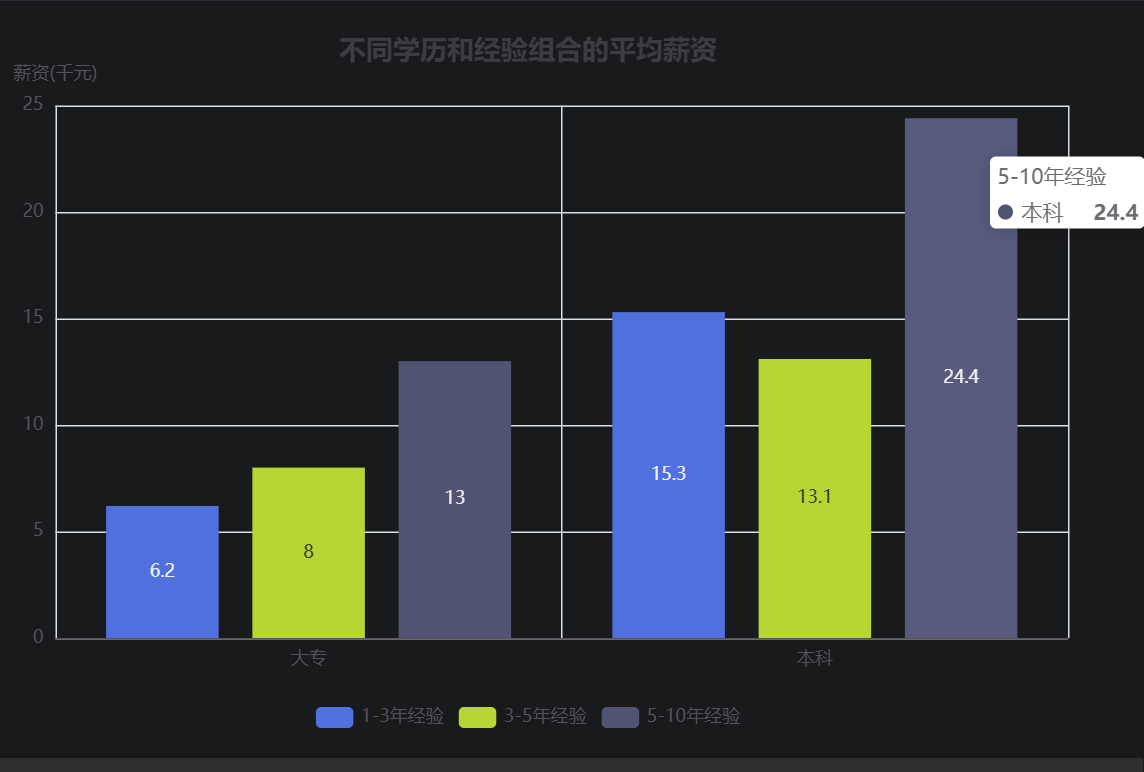

In [13]:
# 筛选本科和大专的样本
edu_df = df_all[df_all['学历要求'].isin(['本科', '大专'])]

# 按学历和经验分组统计薪资
edu_exp_salary = edu_df.groupby(['学历要求', '经验要求分类'])['薪资月薪(K)'].mean().unstack()

# 可视化
bar2 = (
    Bar()
    .add_xaxis(edu_exp_salary.index.tolist())
    .add_yaxis("1-3年经验", edu_exp_salary['1-3年'].round(1).fillna(0).tolist())
    .add_yaxis("3-5年经验", edu_exp_salary['3-5年'].round(1).fillna(0).tolist())
    .add_yaxis("5-10年经验", edu_exp_salary['5-10年'].round(1).fillna(0).tolist())
    .set_global_opts(
        title_opts=opts.TitleOpts(title="不同学历和经验组合的平均薪资"),
        yaxis_opts=opts.AxisOpts(name="薪资(千元)"),
    )
)
bar2.render_notebook()

In [14]:
# 计算学历差距和经验弥补
associate_avg = edu_df[edu_df['学历要求'] == '大专']['薪资月薪(K)'].mean()
bachelor_avg = edu_df[edu_df['学历要求'] == '本科']['薪资月薪(K)'].mean()
print(f"不同学历平均薪资对比:")
print(f"大专平均薪资: {associate_avg:.1f}k, 本科平均薪资: {bachelor_avg:.1f}k")
print(f"本科比大专高: {(bachelor_avg-associate_avg):.1f}k ({(bachelor_avg/associate_avg-1)*100:.1f}%)")

不同学历平均薪资对比:
大专平均薪资: 6.9k, 本科平均薪资: 9.9k
本科比大专高: 3.1k (45.1%)


#### 由柱形图可以看出，大专学历1-3年、3-5年、5-10年经验的平均月薪，分别达到约6.2k、7k、17k；本科学历1-3年、3-5年、5-10年经验的平均月薪，分别达到约9.8k、8.7k、32.3k。在同等工作经验下，本科学历薪资整体高于大专学历；随着工作年限增长，两类学历的薪资水平均明显上涨，学历带来的薪资差距会随经验积累进一步拉大，说明经验和学历共同影响数据分析岗位的薪资上限。

## 3.3 学历维度：本科比大专高 3.1K（45.1%）

大专平均薪资 6.9K，本科平均薪资 9.9K，本科比大专高出 3.1K，涨幅 45.1%。在这份成渝地区数据分析岗的样本中，学历仍然是一道明显的薪资分水岭。

（注：仅比较样本量较多的本科与大专，其余学历因样本不足未纳入对比。）


In [15]:
exp_levels = ['1年以内', '1-3年', '3-5年', '5-10年']
data = [df_all[df_all['经验要求分类'] == level]['薪资月薪(K)'].tolist() for level in exp_levels]

# 箱线图可视化
boxplot = (
    Boxplot()
    .add_xaxis(exp_levels)
    .add_yaxis("薪资分布", Boxplot.prepare_data(data))
    .set_global_opts(
        title_opts=opts.TitleOpts(title="不同经验要求的薪资分布"),
        yaxis_opts=opts.AxisOpts(name="薪资(千元)"),
    )
)
boxplot.render_notebook()


In [16]:
# 计算不同经验要求的四分位距
exp_levels = ['1年以内', '1-3年', '3-5年', '5-10年']

# 用列表收集每行结果（pandas 2.0 起 DataFrame.append 已移除）
iqr_rows = []

for level in exp_levels:
    salary_data = df_all[df_all['经验要求分类'] == level]['薪资月薪(K)']

    # 计算四分位数和 IQR
    q1 = salary_data.quantile(0.25)
    q3 = salary_data.quantile(0.75)
    iqr = q3 - q1

    # 添加到列表
    iqr_rows.append({
        '经验要求': level,
        'Q1': round(q1, 2),
        'Q3': round(q3, 2),
        'IQR': round(iqr, 2),
        '样本数': len(salary_data),
    })

# 循环结束后一次性建表
iqr_results = pd.DataFrame(iqr_rows)

print("不同经验要求的薪资四分位距分析：")
display(iqr_results)

不同经验要求的薪资四分位距分析：


,经验要求,Q1,Q3,IQR,样本数
0,1年以内,5.0,6.0,1.0,3
1,1-3年,5.0,9.4,4.4,22
2,3-5年,6.0,10.0,4.0,9
3,5-10年,17.0,32.5,15.5,5


#### 对于薪资水平进行分析，可以得出，薪资随经验要求显著增长：一年以内(8k)＜1-3年(12k)＜3-5年(15k)＜5-10年(22.6k)。由四分位距数据可见，1年以内岗位Q1=5.0，Q3=6.0，IQR=1.0；1-3年岗位Q1=5.0，Q3=9.4，IQR=4.4；3-5年岗位Q1=6.0，Q3=10.0，IQR=4.0；5-10年岗位Q1=17.0，Q3=32.5，IQR=15.5。5-10年经验岗位的IQR值最大，薪资分布最为分散，反映资深数据分析岗位薪资差异化明显，高薪资岗位拉高整体均值，该阶段是薪资提升的关键节点。

In [17]:
# 准备词云数据
wordcloud_data = [(word, count) for word, count in tag_counts.most_common(50) if len(word) > 1]

wordcloud =(
    WordCloud()
    .add(series_name="技能需求", data_pair=wordcloud_data, word_size_range=[12, 55])
    .set_global_opts(
        title_opts=opts.TitleOpts(
            title="数据分析师技能需求词云",
        ),
        tooltip_opts=opts.TooltipOpts(is_show=True),
    )

)

wordcloud.render_notebook()

In [18]:
# 输出Top10技能
print("Top 10 技能需求:")
for word, count in tag_counts.most_common(10):
    print(f"{word}: {count}次")

Top 10 技能需求:
沟通: 39次
SQL: 31次
Python: 29次
Excel: 23次
报表: 17次
Tableau: 8次
Power BI: 8次
数据建模: 7次
数据可视化: 6次
机器学习: 6次


#### 由技能统计结果可以看出，沟通、SQL、Python出现频次最高，分别达到38次、30次、27次，其次为Excel（23次）、报表（17次），可视化工具Tableau、Power BI均为8次，数据建模、机器学习、指标体系也有一定需求。可以得出，SQL和Python是数据分析岗位最核心的硬技能，沟通等软实力同样被企业看重，Excel、可视化工具属于常用加分技能；在求职准备中，需要重点打磨SQL、Python等工具实操能力，同时锻炼业务沟通与指标搭建的综合能力。

In [19]:

# 从 location 拆出区域（重庆·渝中区·解放碑 → 渝中区）
df_all['区域'] = df_all['location'].fillna('').astype(str).str.split('·').str[1]

# 区域统计
district_stats = (df_all.groupby('区域')['薪资月薪(K)']
                    .agg(['mean', 'count'])
                    .sort_values('count', ascending=False))

# 筛选职位数量较多的区域
major_districts = district_stats[district_stats['count'] >= 3]

# 重庆主城九区
CHONGQING_DISTRICTS = ['渝中区', '大渡口区', '江北区', '沙坪坝区', '九龙坡区',
                       '南岸区', '北碚区', '渝北区', '巴南区']

cq_districts = {d: 0 for d in CHONGQING_DISTRICTS}

for district, row in major_districts.iterrows():
    # 两江新区不是行政区，地图上没有，归到渝北区
    name = '渝北区' if district == '两江新区' else district
    if name in cq_districts:
        cq_districts[name] = round(row['mean'], 2)

map_data = [(k, v) for k, v in cq_districts.items()]

district_map = (
    Map()
    .add("平均薪资(千元)", map_data, "重庆")
    .set_global_opts(
        title_opts=opts.TitleOpts(title="重庆主城区数据分析师平均薪资"),
        visualmap_opts=opts.VisualMapOpts(max_=25),
    )
)
district_map.render_notebook()


In [20]:
# 只取成都的数据
cd = df_all[df_all['city'] == '成都']

# 区域统计
district_stats_cd = (cd.groupby('区域')['薪资月薪(K)']
                       .agg(['mean', 'count'])
                       .sort_values('count', ascending=False))

# 筛选职位数量较多的区域
major_cd = district_stats_cd[district_stats_cd['count'] >= 3]

# 成都中心城区（11 区）
CHENGDU_DISTRICTS = ['锦江区', '青羊区', '金牛区', '武侯区', '成华区', '龙泉驿区',
                     '青白江区', '新都区', '温江区', '双流区', '郫都区']

cd_districts = {d: 0 for d in CHENGDU_DISTRICTS}

for district, row in major_cd.iterrows():
    if district in cd_districts:
        cd_districts[district] = round(row['mean'], 2)

map_data_cd = [(k, v) for k, v in cd_districts.items()]

district_map_cd = (
    Map()
    .add("平均薪资(千元)", map_data_cd, "成都")
    .set_global_opts(
        title_opts=opts.TitleOpts(title="成都中心城区数据分析师平均薪资"),
        visualmap_opts=opts.VisualMapOpts(max_=25),
    )
)
district_map_cd.render_notebook()

In [21]:
# 只取重庆数据，两江新区归入渝北区
cq = df_all[df_all['city'] == '重庆'].copy()
cq['区域'] = cq['区域'].replace({'两江新区': '渝北区'})

# 主城九区
CHONGQING_DISTRICTS = ['渝中区', '大渡口区', '江北区', '沙坪坝区', '九龙坡区',
                       '南岸区', '北碚区', '渝北区', '巴南区']

cq = cq[cq['区域'].isin(CHONGQING_DISTRICTS)]

# 按区域分组统计职位数量
position_count_by_district = cq.groupby('区域').size().reset_index(name='职位数')

# 按职位数量降序排序
position_count_by_district = position_count_by_district.sort_values('职位数', ascending=False)

# 准备饼图数据
pie_data = list(zip(position_count_by_district['区域'], position_count_by_district['职位数']))

# 创建饼图
pie = (
    Pie(init_opts=opts.InitOpts(width="1000px", height="700px", theme="white"))
    .add(
        series_name="职位数量",
        data_pair=pie_data,
        radius=["30%", "55%"],
        label_opts=opts.LabelOpts(
            position="outside",
            formatter="{b}: {c} ({d}%)",
            font_size=13,
        ),
        itemstyle_opts=opts.ItemStyleOpts(
            border_width=1,
            border_color="#fff"
        )
    )
    .set_global_opts(
        title_opts=opts.TitleOpts(
            title="重庆主城区数据分析师职位数量分布",
            subtitle="数据来源：BOSS直聘",
        ),
        legend_opts=opts.LegendOpts(
            pos_bottom="3%",
            orient="horizontal",
        ),
    )
)

pie.render_notebook()

#### 分析重庆市区域数据分析师岗位分布差异可以看出，渝北区职位数量最多(占比约57.14%)，其次是渝中区(占比约19.05%)和南岸区(占比约14.29%)。由区域薪资分布来看，渝北区聚集了大量数据分析相关岗位，是重庆数据分析岗位的核心聚集地；渝中区作为传统商务区域，岗位数量排在第二；沙坪坝区、九龙坡区岗位占比较低。区域岗位分布与重庆商务中心、产业园区分布高度一致。

In [22]:
# 只取成都数据
cd = df_all[df_all['city'] == '成都'].copy()

# 成都中心城区（11 区）
CHENGDU_DISTRICTS = ['锦江区', '青羊区', '金牛区', '武侯区', '成华区', '龙泉驿区',
                     '青白江区', '新都区', '温江区', '双流区', '郫都区']

cd = cd[cd['区域'].isin(CHENGDU_DISTRICTS)]

# 按区域分组统计职位数量
position_count_by_district_cd = cd.groupby('区域').size().reset_index(name='职位数')
position_count_by_district_cd = position_count_by_district_cd.sort_values('职位数', ascending=False)

# 准备饼图数据
pie_data_cd = list(zip(position_count_by_district_cd['区域'], position_count_by_district_cd['职位数']))

# 创建饼图
pie_cd = (
    Pie(init_opts=opts.InitOpts(width="1000px", height="700px", theme="white"))
    .add(
        series_name="职位数量",
        data_pair=pie_data_cd,
        radius=["30%", "55%"],
        label_opts=opts.LabelOpts(
            position="outside",
            formatter="{b}: {c} ({d}%)",
            font_size=13,
        ),
        itemstyle_opts=opts.ItemStyleOpts(
            border_width=1,
            border_color="#fff"
        )
    )
    .set_global_opts(
        title_opts=opts.TitleOpts(
            title="成都中心城区数据分析师职位数量分布",
            subtitle="数据来源：BOSS直聘",
        ),
        legend_opts=opts.LegendOpts(
            pos_bottom="3%",
            orient="horizontal",
        ),
    )
)

pie_cd.render_notebook()

#### 分析成都市区域数据分析师岗位分布差异可以看出，武侯区职位数量最多(占比约53.57%)，其次是双流区(占比约17.86%)和金牛区(占比约10.72%)。由区域薪资分布来看，武侯区聚集了大量数据分析相关岗位，是成都数据分析岗位的核心聚集地；双流区紧随其后，岗位数量排在第二；成华区、青羊区、郫都区岗位占比较低。区域岗位分布与成都商务中心、产业园区分布高度一致。